In [1]:
from qldpc import circuits
import stim
import directional_tile_codes as dtc
from qldpc.circuits import SyndromeMeasurementStrategy

In [8]:
def get_physical_circuit(strategy: SyndromeMeasurementStrategy, circuit: stim.Circuit):
    physical_circuit = stim.Circuit()

    qubit_ids = strategy.get_qubit_ids()
    physical_ids = strategy.layout.position_to_id(qubit_ids)

    for position, qubit_id in physical_ids.items():
        physical_circuit.append(
            "QUBIT_COORDS",
            [qubit_id],
            [position.x, position.y],
        )

    for instruction in circuit.flattened():
        if instruction.name != "QUBIT_COORDS":
            physical_circuit.append(instruction)
    
    return physical_circuit

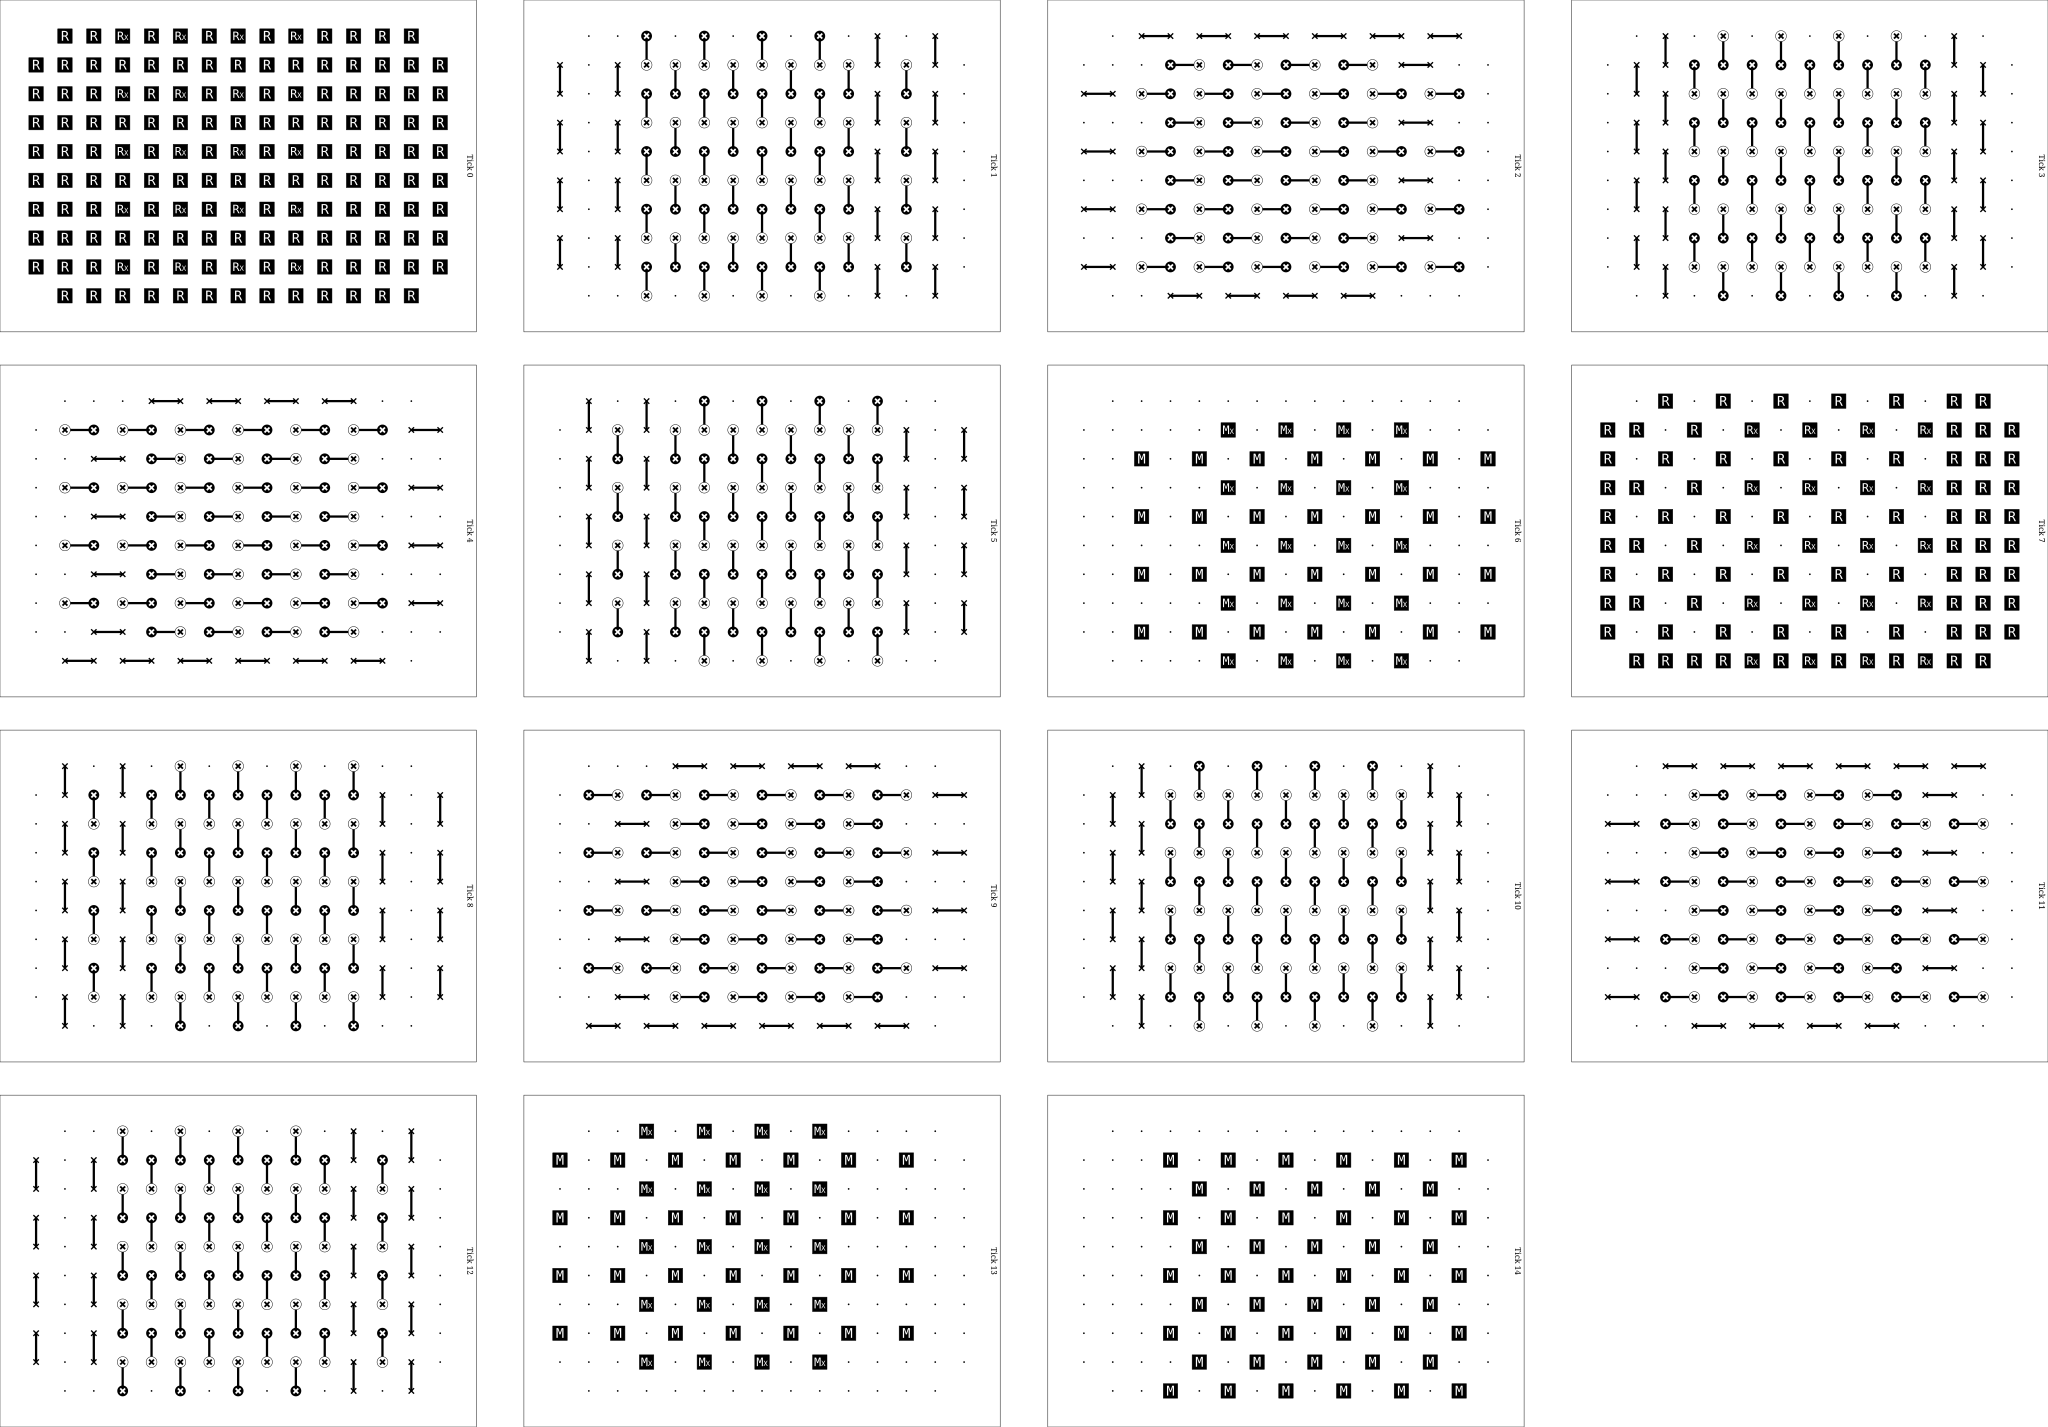

In [12]:
code = dtc.DirectionalTileCode(M=4, N=4, word=dtc.DirectionalWord("NESEN"))
strategy = dtc.DirectionalSyndromeMeasurement(
    code,
    include_coordinates=False,
)

circuit_z = circuits.get_memory_experiment(
    code.css_code,
    basis="Z",
    num_rounds=1,
    qubit_ids=strategy.get_qubit_ids(),
    syndrome_measurement_strategy=strategy,
)

physical_circuit = get_physical_circuit(strategy, circuit_z)
display(physical_circuit.diagram("timeslice-svg"))

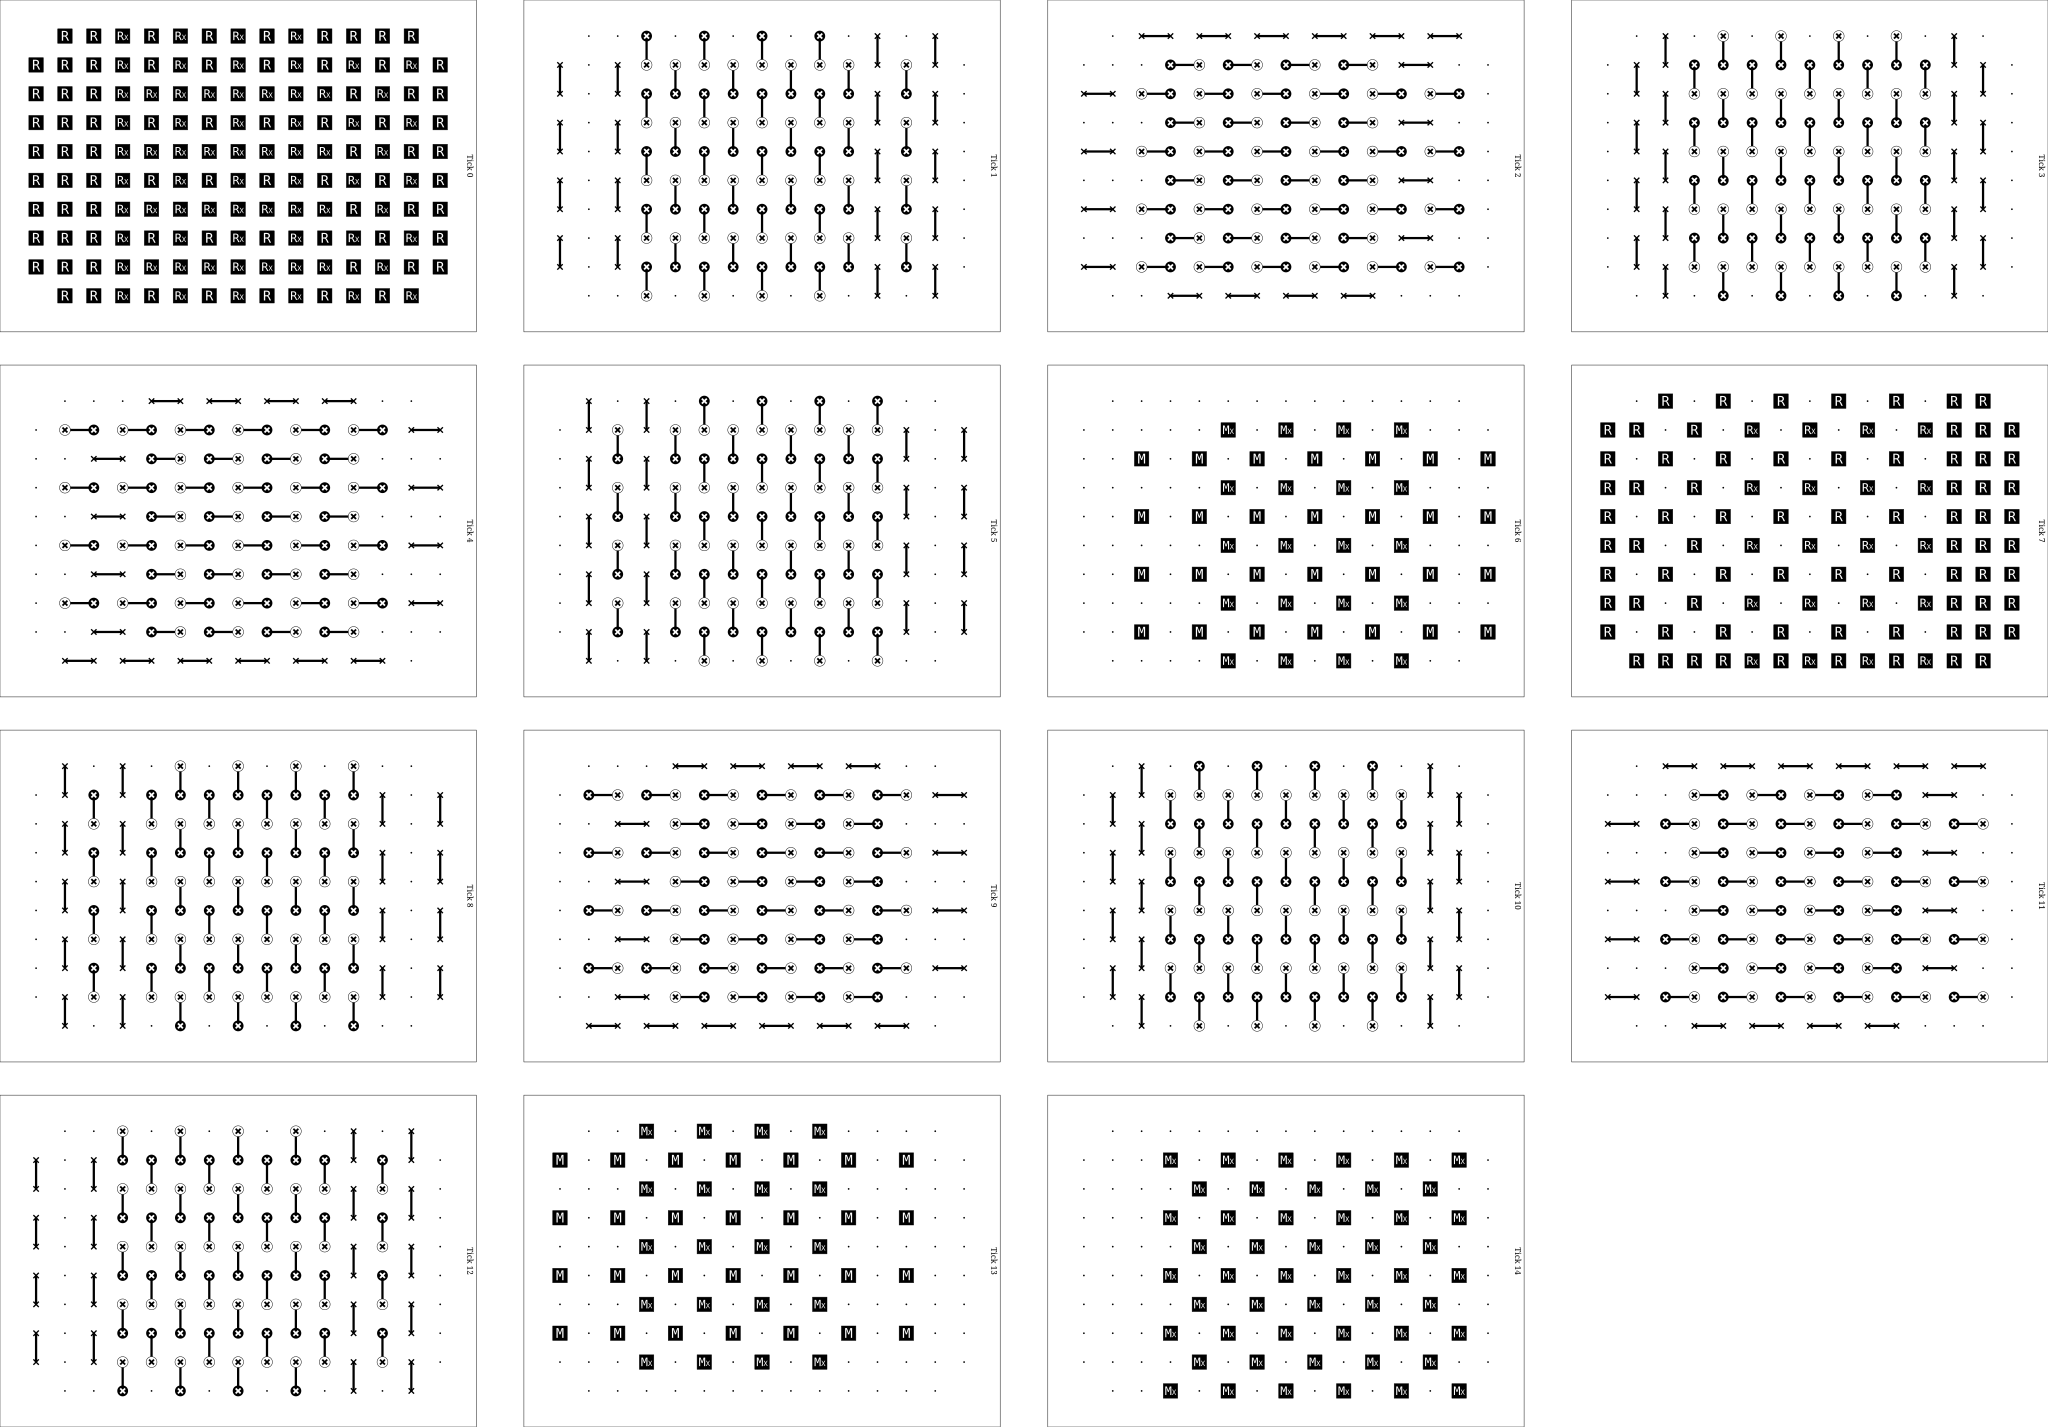

In [14]:
code = dtc.DirectionalTileCode(M=4, N=4, word=dtc.DirectionalWord("NESEN"))
strategy = dtc.DirectionalSyndromeMeasurement(
    code,
    include_coordinates=False,
)

circuit_x = circuits.get_memory_experiment(
    code.css_code,
    basis="X",
    num_rounds=1,
    qubit_ids=strategy.get_qubit_ids(),
    syndrome_measurement_strategy=strategy,
)

physical_circuit = get_physical_circuit(strategy, circuit_x)
display(physical_circuit.diagram("timeslice-svg"))

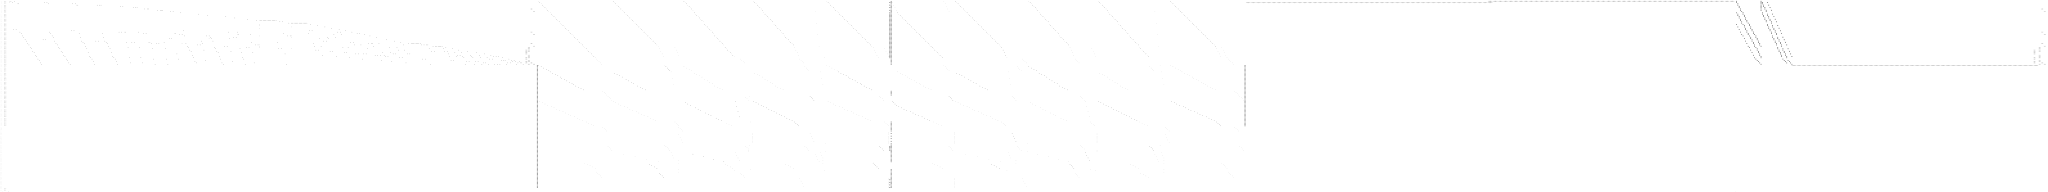

In [18]:
code = dtc.DirectionalTileCode(M=4, N=4, word=dtc.DirectionalWord("NESEN"))
strategy = dtc.DirectionalSyndromeMeasurement(
    code,
    include_coordinates=False,
)

circuit = circuits.get_memory_experiment(
    code.css_code,
    basis=None,
    num_rounds=1,
    qubit_ids=strategy.get_qubit_ids(),
    syndrome_measurement_strategy=strategy,
)

display(circuit.diagram("timeline-svg"))